In [1]:
import xarray as xr
import earthkit.plots
import earthkit.geo.cartography

### Downloaded Phase 2 data using the polytope-client

- Zeitraum: 1 Monat (Jänner 2020) 
- stündliche Auflösung
- Domäne: Greater Alpine Region
- HEALpix 512 grid 
- Model: IFS-NEMO/IFS-FESOM/ICON
- Datenmenge: 200 MB

In [3]:
# Folder with the downloaded Zarr stores
base_dir = "/jetfs/scratch/mmeindl/HighResLearn/download/cloud4geo_km-scale"

In [4]:
# Models to compare: key = model name used in the request / file name,
# value = title shown above the subplot
models = {
    "ifs-nemo": "IFS-NEMO",
    "ifs-fesom": "IFS-FESOM",
    "icon": "ICON",
}

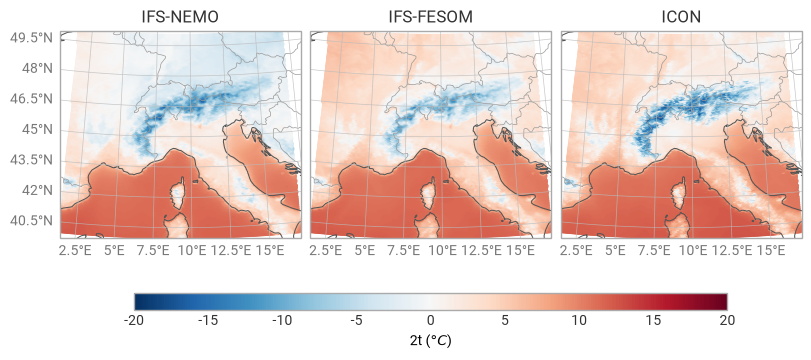

In [22]:
# Create a figure with 1 row and 3 columns (one map per model)
figure = earthkit.plots.Figure(rows=1, columns=len(models))
 
for col, (model, label) in enumerate(models.items()):
    # Open the Zarr store of this model
    zarr_path = f"{base_dir}/t2m_{model}_ssp3-7.0_2020-01_GAR.zarr"
    ds = xr.open_zarr(zarr_path)
    #print(f"--- {label} ---")
    #print(ds)
 
    # Temporal mean over all hourly time steps of January
    ds_mean = ds["2t"].mean(dim="datetimes")
 
    # Add a map in column `col` of the figure
    # (domain could also be the GAR box: [1.5, 17.0, 40.0, 50.0] = [W, E, S, N])
    subplot = figure.add_map(0, col, domain=[1.5, 17.0, 40.0, 50.0])
 
    # Same units, colour map and value range for all models,
    # so the panels are directly comparable and can share one legend
    subplot.point_cloud(
        ds_mean,
        units="celsius",
        cmap="RdBu_r",
        vmin=-20,
        vmax=20,
    )
 
    # Panel title with the model name
    subplot.title(label)
    
# Map features, applied to every subplot
figure.coastlines()
figure.borders()
figure.gridlines()
 
# One shared colour bar for all panels (valid because vmin/vmax are identical)
figure.legend()
 
# Overall title of the figure
#figure.title("Mean 2 m temperature, January 2020, SSP3-7.0")
 
figure.show()
#figure.save("t2m_models_GAR.png", dpi=300)